# 03 — Fusion Audio–Video dan Sintesis Kesiapan Riset

> **Dataset:** RAVDESS paired AV · **Target:** emotion, bukan fatigue  
> **Unit:** recording pada aktor holdout · **Visual:** appearance HOG 2 FPS, bukan blink/PERCLOS  
> **Mode default:** DEMO — hasil FULL tersimpan + ekstraksi satu klip dan inference langsung

[README proyek](../../README.md) · [Sumber RAVDESS](https://zenodo.org/records/1188976) · [Batas metodologi](../../reports/limitations.md) · [Reproduksi](README.md)

## Ringkasan untuk Pembaca

Audio dan gambar dapat membawa informasi yang berbeda dari satu rekaman. Kita mengekstrak keduanya, melatih baseline unimodal dan fusion, lalu menilai rekaman aktor yang tidak masuk training. Tugas pengujian ini adalah **emosi aktor**; keberhasilan prosesnya membantu menyiapkan penelitian fatigue, tetapi bukan skor deteksi fatigue ATC.

### Rute presentasi 10–15 menit

1. [Pertanyaan dan peta bukti](#1-pertanyaan-dan-peta-bukti) — 2 menit.
2. [Pasangan AV dan fitur langsung](#2-pasangan-asli-dan-transformasi-fitur) — 2 menit.
3. [Split dan keterbatasan](#3-eda-dan-split-aktor-yang-dibekukan) — 2 menit.
4. [Training serta hasil](#4-training-dan-evaluasi-empat-model) — 3 menit.
5. [Ablation serta inference](#5-modalitas-hilang-dan-inference-heldout) — 2 menit.
6. [Sintesis untuk Prof](#6-sintesis-kesiapan-penelitian) — 2 menit.

Detail kode tetap tersedia dalam notebook yang sama. Tidak diperlukan variabel dari notebook sebelumnya.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')

Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="1-pertanyaan-dan-peta-bukti"></a>

## 1. Pertanyaan dan peta bukti

**Pertanyaan:** apakah audio dan video dari recording asli yang sama bisa diproses, dilatih, dan dievaluasi secara adil terhadap model satu modalitas?

**Fusion** berarti menggabungkan informasi beberapa modalitas. Pada baseline ini, vektor audio dan visual disambung (*feature concatenation*), lalu classifier mempelajari label emotion. **Macro F1** adalah rerata F1 tiap kelas; F1 menyeimbangkan ketepatan prediksi dan kemampuan menemukan anggota kelas. **Balanced accuracy** adalah rerata recall tiap kelas.

Fatigue = kelelahan akibat tuntutan berkelanjutan; sleepiness = kecenderungan tertidur; workload = tuntutan mental; stress = respons tekanan. **Emotion** dan **eye state** adalah label berbeda lagi. Kita tidak mengganti satu target dengan target lain.

| Sumber bukti | Pertanyaan yang benar-benar diuji | Yang belum dibuktikan |
| :--- | :--- | :--- |
| ATCOSIM | Bisakah suara ATC menjadi fitur? | Akurasi fatigue dari suara |
| MRL | Bisakah gambar mata dikenali open/closed? | Fatigue operator |
| DROZY | Bisakah fitur mata memperkirakan KSS sleepiness? | Real-time fatigue ATC |
| RAVDESS | Bisakah paired AV dipakai untuk emotion fusion? | Fusion fisiologis fatigue ATC |

RAVDESS: Livingstone & Russo (2018), DOI `10.1371/journal.pone.0196391`, CC BY-NC-SA 4.0. Notebook mempertahankan atribusi dan tidak membagikan media sumber. Tabel/grafik agregat dan ilustrasi tanpa wajah cukup untuk presentasi proses.

In [2]:
ravdess_manifest = local_manifest(config['fusion']['ravdess_manifest'],target='emotion')
ravdess_rights = {'source':'https://zenodo.org/records/1188976',
                  'variant':'AV speech; actors 01–08; normal intensity; statement 01; two repetitions',
                  'rights':'CC BY-NC-SA 4.0; Livingstone & Russo (2018)', 'public_preview':'aggregate charts, no raw faces/voice'}
ravdess_limits = ['emotion not fatigue; 8 actors / tiny heldout subset',
                  'original male-only train, female-only validation/test; demographic domain shift',
                  'face HOG 2fps is appearance, not blink/EAR/PERCLOS',
                  'inference ablation is not missing-modality robustness training',
                  'previously observed fixed holdout; rerun is not new independent evidence']
if RUN_MODE=='FULL':
    fusion_run = Run.create('ravdess_emotion','03_multimodal_fusion.ipynb',config,ravdess_manifest,
                            'audio-egemapsv02-mfcc13-v1; sampled-face-hog-2fps-v1',ravdess_rights,ravdess_limits)
else:
    fusion_run,fusion_metrics = cached_run('ravdess_emotion',config)
fusion_book = FigureBook(fusion_run,RUN_MODE,config)
run_card(fusion_run,RUN_MODE,'FULL: dihitung pada evaluasi' if RUN_MODE=='FULL' else
         f"Emotion Macro F1 {fusion_metrics['models']['audio_visual']['test']['macro_f1']:.4f} / 32 klip test")

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T081858104344Z_seed42_75d379` |
| Status eksperimen sumber | completed |
| Dataset / target | ravdess / emotion |
| Sampel / subjek | 128 / 8 |
| Unit evaluasi | AV_recording; held-out actor |
| Hasil utama | Emotion Macro F1 0.4549 / 32 klip test |

<a id="2-pasangan-asli-dan-transformasi-fitur"></a>

## 2. Pasangan asli dan transformasi fitur

File RAVDESS modality `01` berisi **dua stream dalam container AV yang sama**. Identitas file dan checksum menjadi bukti pasangan; kita tidak menyambungkan dataset atau waktu yang tidak berhubungan. Timestamps stream diperiksa melalui `ffprobe`.

Audio menjadi **88 eGeMAPS** (paket ringkasan fitur suara) + **26 MFCC** (rerata/simpangan baku 13 koefisien spektral). Visual menjadi **HOG** (ringkasan arah tepi wajah) yang disampel 2 frame/detik dan diringkas rerata/simpangan baku. **Sampling 2 FPS tidak memadai untuk mengukur kedipan**; cabang fisiologis EAR/PERCLOS untuk paired ATC belum diuji di sini.

In [3]:
from atc_fatigue.research.data import paired_sample, pseudonym
from atc_fatigue.models.baselines import classification_metrics
predeclared_split = frozen_split(ravdess_manifest,config['frozen_splits']['ravdess_emotion'])
example_id = predeclared_split.loc[predeclared_split.split.eq('test'),'sample_id'].iloc[0]
heldout_source = ravdess_manifest[ravdess_manifest.sample_id.eq(example_id)].iloc[0]
live_output = fusion_run.file('features/live_example.wav') if RUN_MODE=='FULL' else fusion_book.directory.parent / 'live_example.wav'
live_paired_features = paired_sample(heldout_source,config,live_output)
display(pd.DataFrame([{'Contoh holdout':pseudonym(example_id),'Target':'emotion',
                       'Label asli':EMOTIONS[int(heldout_source.target_value)],
                       'Pasangan':'audio + video dari satu file AV',
                       'Durasi video (s)':live_paired_features['video_duration_ms']/1000,
                       'Offset start audio − video (s)':live_paired_features['stream_offset_seconds'],
                       'Audio tersedia':live_paired_features['audio_available'],
                       'Video tersedia':live_paired_features['video_available']}]))
assert live_paired_features['paired_recording_verified']
assert heldout_source.sample_id in set(predeclared_split[predeclared_split.split.eq('test')].sample_id)

,Contoh holdout,Target,Label asli,Pasangan,Durasi video (s),Offset start audio − video (s),Audio tersedia,Video tersedia
0,contoh-61881241,emotion,Netral,audio + video dari satu file AV,3.636967,0.0,True,True


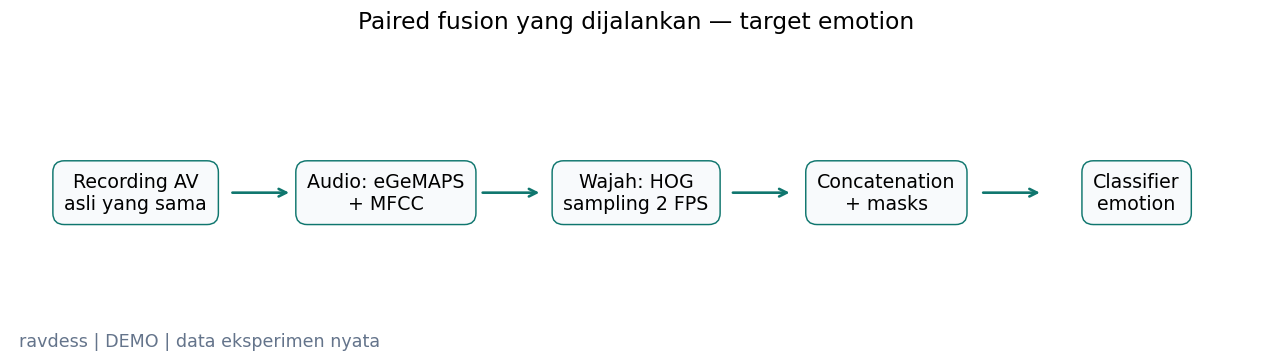

**Yang terlihat:** Kedua modalitas berasal dari checksum file sumber yang sama.

**Artinya:** Baseline dapat menguji manfaat fitur gabungan tanpa membuat pasangan palsu.

**Perlu diingat:** Diagram ini memakai HOG appearance; cabang EAR/PERCLOS fatigue ATC adalah pekerjaan berikutnya.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [4]:
fig = flow(['Recording AV\nasli yang sama', 'Audio: eGeMAPS\n+ MFCC', 'Wajah: HOG\nsampling 2 FPS', 'Concatenation\n+ masks', 'Classifier\nemotion'],
           COLORS['fusion'],'Paired fusion yang dijalankan — target emotion')
fusion_book.show(fig,'alur_paired_fusion','Kedua modalitas berasal dari checksum file sumber yang sama.',
                 'Baseline dapat menguji manfaat fitur gabungan tanpa membuat pasangan palsu.',
                 'Diagram ini memakai HOG appearance; cabang EAR/PERCLOS fatigue ATC adalah pekerjaan berikutnya.')

### Ekstraksi seluruh subset pada FULL

Satu contoh holdout sudah diproses langsung pada kedua mode. FULL meneruskan ekstraksi untuk seluruh recording lokal, menyimpan audio turunan hanya di run baru, dan memverifikasi source checksum/stream. DEMO menggunakan tabel FULL terverifikasi untuk bagian mahal, kemudian mencocokkan contoh langsung dengan cache.

**Availability mask** menandai fitur tersedia atau hilang. Kegagalan tidak diubah menjadi pitch nol atau HOG nol yang dianggap pengukuran asli; preprocessing menangani nilai hilang berdasarkan training saja.

In [5]:
if RUN_MODE=='FULL':
    paired_rows = []
    extraction_started = time.perf_counter()
    for index,row in ravdess_manifest.iterrows():
        if row.sample_id==example_id:
            paired_rows.append(live_paired_features)
        else:
            decoded_audio = fusion_run.file(f'features/decoded_audio/{row.sample_id}.wav')
            paired_rows.append(paired_sample(row,config,decoded_audio))
        if (index+1)%32==0:
            print(f'Ekstraksi AV {index+1}/{len(ravdess_manifest)} selesai')
    paired_features = pd.DataFrame(paired_rows)
    fusion_data = frozen_split(paired_features,config['frozen_splits']['ravdess_emotion'])
    fusion_run.log('extract_all_paired',{'rows':len(fusion_data),'seconds':time.perf_counter()-extraction_started})
else:
    fusion_data = pd.read_parquet(fusion_run.path / 'features/features.parquet')
    assert set(fusion_data.sample_id)==set(ravdess_manifest.sample_id)
audio_columns = [c for c in fusion_data if c.startswith(('egemaps__','mfcc_'))]
visual_columns = [c for c in fusion_data if c.startswith('visual_hog_')]
fusion_columns = audio_columns+visual_columns+['audio_available','video_available']
assert fusion_data.paired_recording_verified.all() and len(audio_columns)==114
np.testing.assert_allclose(fusion_data.loc[fusion_data.sample_id.eq(example_id),audio_columns+visual_columns].iloc[0].to_numpy(float),
                           np.array([live_paired_features[c] for c in audio_columns+visual_columns]),equal_nan=True,rtol=1e-5,atol=1e-7)
display(fusion_data[['duration_seconds','face_detection_rate','audio_available','video_available']].head())
display(pd.DataFrame([{'Fitur audio':len(audio_columns),'Fitur visual':len(visual_columns),
                       'Masks':2,'Dimensi fusion':len(fusion_columns)}]))

,duration_seconds,face_detection_rate,audio_available,video_available
0,3.306687,1.0,True,True
1,3.349312,1.0,True,True
2,3.541313,1.0,True,True
3,3.605313,1.0,True,True
4,3.477313,1.0,True,True


,Fitur audio,Fitur visual,Masks,Dimensi fusion
0,114,3528,2,3644


<a id="3-eda-dan-split-aktor-yang-dibekukan"></a>

## 3. EDA dan split aktor yang dibekukan

EDA (*exploratory data analysis*) memeriksa apa yang benar-benar ada sebelum menafsirkan model. Delapan emotion classes berasal dari filename resmi. Subset hanya normal intensity dan satu statement, sehingga variasi yang tersedia lebih sempit daripada seluruh RAVDESS.

Split ditahan per aktor: orang yang sama tidak melintasi train/validation/test. Kita memakai keanggotaan run lama, tanpa tuning ulang setelah test diamati. Rerun ini menguji reproduksibilitas dan proses notebook; bukan test independen yang baru.

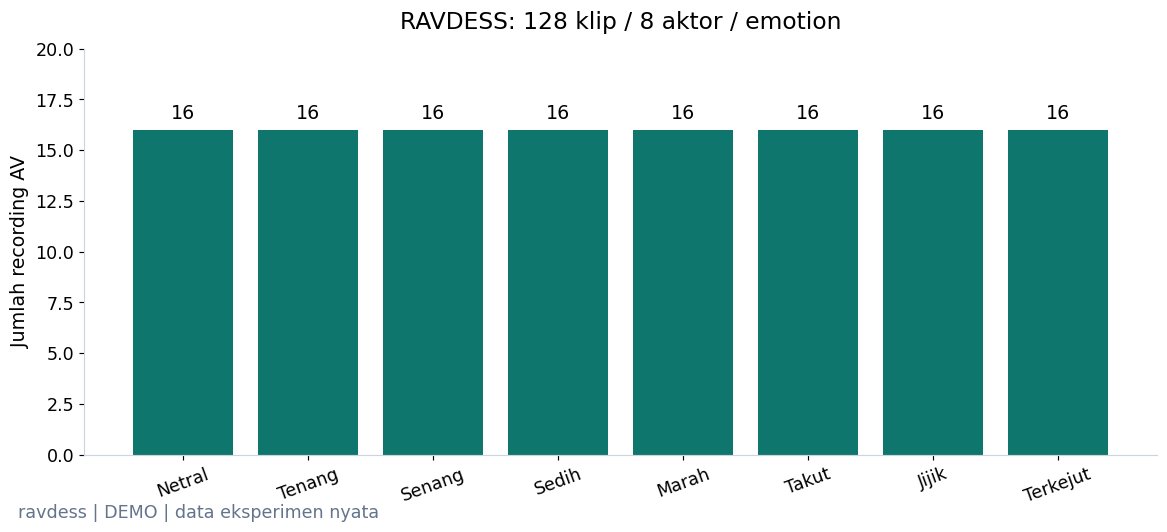

**Yang terlihat:** Setiap kelas memiliki 16–16 klip pada subset ini.

**Artinya:** Keseimbangan label membantu membandingkan model, sementara ukuran aktor tetap kecil.

**Perlu diingat:** Emotion adalah ekspresi aktor; label ini bukan penilaian fatigue operator.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [6]:
class_counts = fusion_data.target_value.value_counts().sort_index()
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar([EMOTIONS[int(x)] for x in class_counts.index],class_counts.values,color=COLORS['fusion'])
ax.bar_label(bars,padding=5)
ax.set(ylabel='Jumlah recording AV',ylim=(0,class_counts.max()*1.25),
       title=f'RAVDESS: {len(fusion_data)} klip / {fusion_data.subject_id.nunique()} aktor / emotion')
ax.tick_params(axis='x',labelrotation=20)
fusion_book.show(fig,'distribusi_emotion',
                 f'Setiap kelas memiliki {class_counts.min()}–{class_counts.max()} klip pada subset ini.',
                 'Keseimbangan label membantu membandingkan model, sementara ukuran aktor tetap kecil.',
                 'Emotion adalah ekspresi aktor; label ini bukan penilaian fatigue operator.')

,Klip,Aktor
split,,
test,32,2
train,64,4
validation,32,2


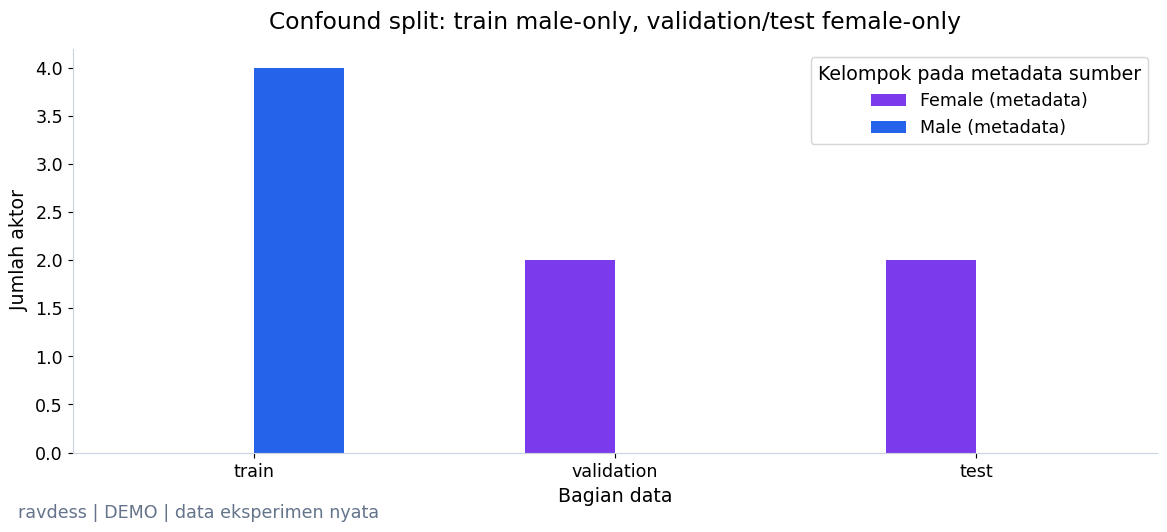

**Yang terlihat:** Keanggotaan split asli memisahkan kelompok metadata male/female sekaligus memisahkan aktor.

**Artinya:** Model mengalami domain shift yang membatasi interpretasi generalisasi dan fairness.

**Perlu diingat:** Kelompok diambil dari konvensi sumber, bukan diinferensikan dari wajah/suara; split tidak diubah sesudah melihat skor.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [7]:
fusion_data['actor_metadata_group'] = fusion_data.subject_id.astype(int).map(lambda actor:'Male (metadata)' if actor%2 else 'Female (metadata)')
split_sizes = fusion_data.groupby('split').size().to_dict()
display(fusion_data.groupby('split').agg(Klip=('sample_id','size'),Aktor=('subject_id','nunique')))
assert fusion_data.groupby('subject_id').split.nunique().max()==1
group_counts = fusion_data.groupby(['split','actor_metadata_group']).subject_id.nunique().unstack(fill_value=0).reindex(['train','validation','test'])
fig,ax = plt.subplots(layout='constrained')
group_counts.plot.bar(ax=ax,rot=0,color=[COLORS['visual'],COLORS['audio']])
ax.set(xlabel='Bagian data',ylabel='Jumlah aktor',title='Confound split: train male-only, validation/test female-only')
ax.legend(title='Kelompok pada metadata sumber')
fusion_book.show(fig,'split_dan_demografi',
                 'Keanggotaan split asli memisahkan kelompok metadata male/female sekaligus memisahkan aktor.',
                 'Model mengalami domain shift yang membatasi interpretasi generalisasi dan fairness.',
                 'Kelompok diambil dari konvensi sumber, bukan diinferensikan dari wajah/suara; split tidak diubah sesudah melihat skor.')

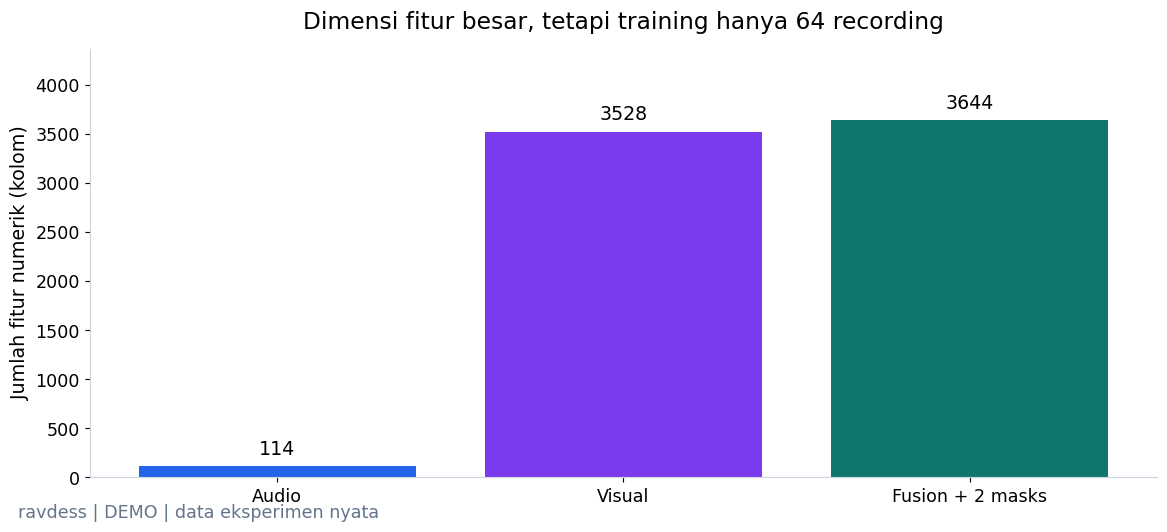

**Yang terlihat:** 3644 kolom fusion dibanding hanya 64 baris training.

**Artinya:** Banyak fitur pada sedikit sampel meningkatkan risiko overfitting; regularisasi tidak menghilangkan kebutuhan data.

**Perlu diingat:** Jumlah kolom bukan ukuran jumlah peserta atau bukti bahwa model lebih baik.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [8]:
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar(['Audio','Visual','Fusion + 2 masks'],[len(audio_columns),len(visual_columns),len(fusion_columns)],
              color=[COLORS['audio'],COLORS['visual'],COLORS['fusion']])
ax.bar_label(bars,padding=5)
ax.set(ylabel='Jumlah fitur numerik (kolom)',ylim=(0,len(fusion_columns)*1.2),
       title=f'Dimensi fitur besar, tetapi training hanya {split_sizes["train"]} recording')
fusion_book.show(fig,'dimensi_fitur',
                 f'{len(fusion_columns)} kolom fusion dibanding hanya {split_sizes["train"]} baris training.',
                 'Banyak fitur pada sedikit sampel meningkatkan risiko overfitting; regularisasi tidak menghilangkan kebutuhan data.',
                 'Jumlah kolom bukan ukuran jumlah peserta atau bukti bahwa model lebih baik.')

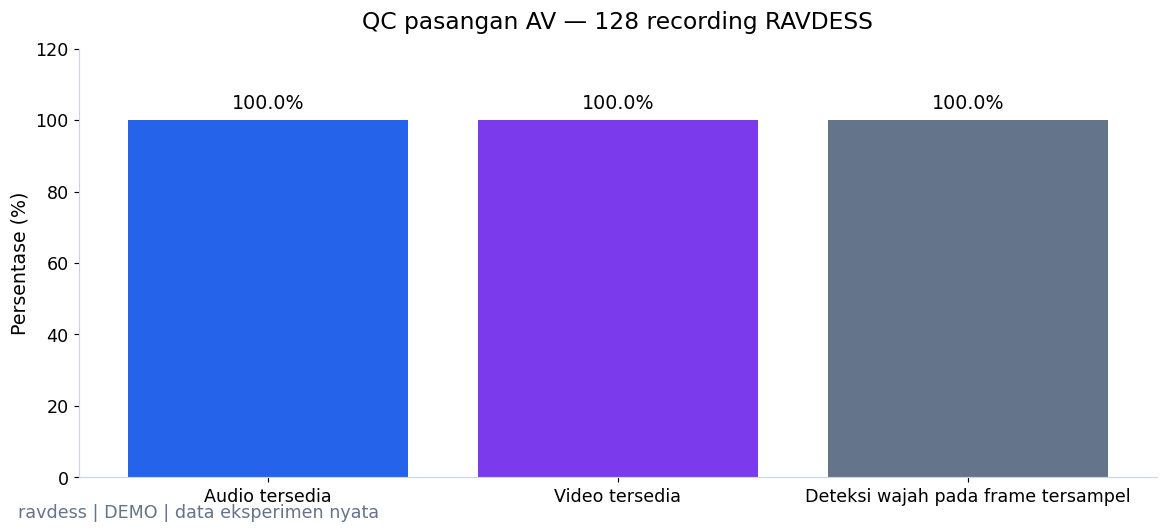

**Yang terlihat:** Audio tersedia 100.0%, video 100.0%; deteksi wajah rerata 100.0%.

**Artinya:** Ketersediaan klip dan keberhasilan deteksi per frame adalah pemeriksaan kualitas yang berbeda.

**Perlu diingat:** Persentase deteksi dirata-ratakan per klip; sampling 2 FPS bukan cakupan temporal untuk kedipan.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [9]:
availability = fusion_data[['audio_available','video_available','face_detection_rate']].mean()
fig,ax = plt.subplots(layout='constrained')
bars = ax.bar(['Audio tersedia','Video tersedia','Deteksi wajah pada frame tersampel'],availability*100,
              color=[COLORS['audio'],COLORS['visual'],COLORS['secondary']])
ax.bar_label(bars,fmt='%.1f%%',padding=5)
ax.set(ylabel='Persentase (%)',ylim=(0,120),title=f'QC pasangan AV — {len(fusion_data)} recording RAVDESS')
fusion_book.show(fig,'qc_availability',
                 f"Audio tersedia {availability.audio_available:.1%}, video {availability.video_available:.1%}; deteksi wajah rerata {availability.face_detection_rate:.1%}.",
                 'Ketersediaan klip dan keberhasilan deteksi per frame adalah pemeriksaan kualitas yang berbeda.',
                 'Persentase deteksi dirata-ratakan per klip; sampling 2 FPS bukan cakupan temporal untuk kedipan.')

<a id="4-training-dan-evaluasi-empat-model"></a>

## 4. Training dan evaluasi empat model

Empat jalur memakai split dan label identik: Dummy mayoritas, audio, visual, dan fusion. Tiga classifier memakai **Logistic Regression**, model linear dengan regularisasi `C=1` dan bobot kelas balanced. Imputer median dan scaler dilatih di training saja.

FULL menjalankan `fit`, menghitung prediksi validation/test, menyimpan model, lalu mencocokkan prediksi hasil reload. DEMO memuat checkpoint dan memverifikasi seluruh prediksi test terhadap file tersimpan. Tidak ada skor buatan atau proses CLI tersembunyi.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
feature_sets = {'dummy_majority':audio_columns,'audio_only':audio_columns,
                'visual_only':visual_columns,'audio_visual':fusion_columns}
fusion_training = fusion_data[fusion_data.split.eq('train')]
fusion_holdout = fusion_data[~fusion_data.split.eq('train')]
if RUN_MODE=='FULL':
    fusion_run.features(fusion_data,fusion_columns,'audio-egemapsv02-mfcc13-v1; sampled-face-hog-2fps-v1')
    fusion_data[['sample_id','subject_id','target_value','source_checksum','split']].to_csv(fusion_run.file('split_manifest.csv'),index=False)
    fusion_scores,fusion_prediction_parts,fitted_models = {},[],{}
    for model_name,columns in feature_sets.items():
        model = DummyClassifier(strategy='most_frequent') if model_name=='dummy_majority' else make_pipeline(
            SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),
            LogisticRegression(C=config['fusion']['logistic_c'],class_weight='balanced',
                               max_iter=config['fusion']['max_iter'],random_state=config['seed']))
        model.fit(fusion_training[columns],fusion_training.target_value)
        save_model(fusion_run,model_name,model,columns,fusion_holdout)
        fitted_models[model_name] = model
        fusion_scores[model_name] = {'reload_verified':True,'feature_count':len(columns)}
        for partition in ['validation','test']:
            part = fusion_data[fusion_data.split.eq(partition)]
            predicted = model.predict(part[columns])
            fusion_scores[model_name][partition] = classification_metrics(part.target_value,predicted,list(EMOTIONS))
            fusion_prediction_parts.append(prediction_table(part,predicted,model_name))
    fusion_predictions = pd.concat(fusion_prediction_parts,ignore_index=True)
    fusion_predictions.to_csv(fusion_run.file('predictions/holdout_predictions.csv'),index=False)
    fusion_metrics = metrics_base(fusion_run,fusion_scores,split_sizes,{str(k):v for k,v in EMOTIONS.items()},'dummy_majority')
else:
    fusion_predictions = pd.read_csv(fusion_run.path / 'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    for model_name in feature_sets:
        verify_cached_predictions(fusion_run,fusion_data[fusion_data.split.eq('test')],fusion_predictions,model_name)

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.027778,0.125,0.125
audio_only,0.311601,0.375,0.375
visual_only,0.279657,0.34375,0.34375
audio_visual,0.454899,0.5,0.5


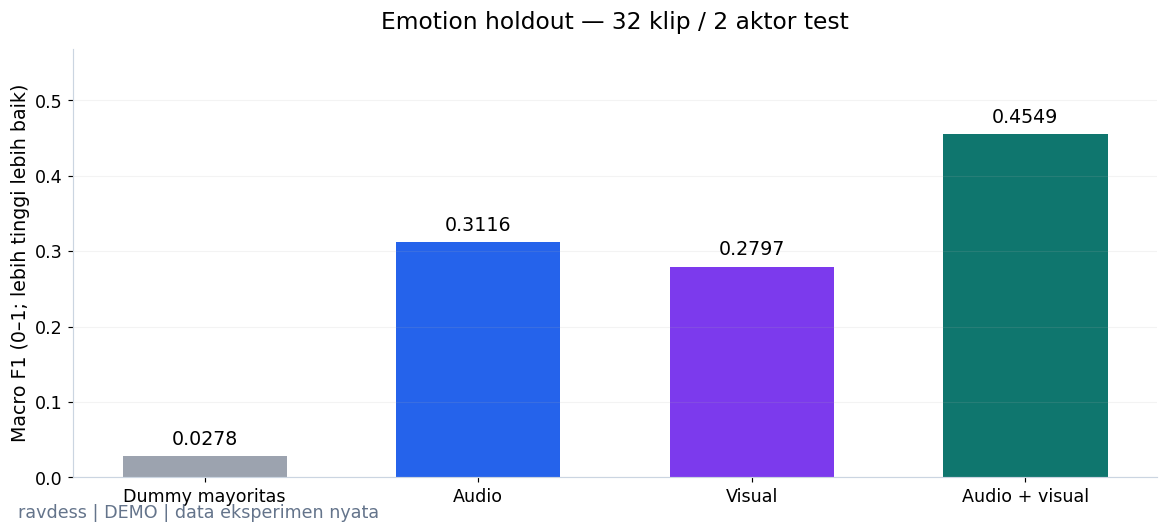

**Yang terlihat:** Fusion F1 0.4549; audio 0.3116; visual 0.2797.

**Artinya:** Pada split kecil yang sama, kita dapat membandingkan empat jalur model secara langsung.

**Perlu diingat:** Dua aktor test dan demographic shift tidak mendukung klaim keunggulan umum atau signifikansi populasi.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [11]:
fusion_test_scores = {name:value['test'] for name,value in fusion_metrics['models'].items()}
display(pd.DataFrame(fusion_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
fig = model_bars(fusion_test_scores,'macro_f1',f'Emotion holdout — {split_sizes["test"]} klip / 2 aktor test',
                 'Macro F1 (0–1; lebih tinggi lebih baik)',COLORS['fusion'])
fusion_book.show(fig,'perbandingan_model_emotion',
                 f"Fusion F1 {fusion_test_scores['audio_visual']['macro_f1']:.4f}; audio {fusion_test_scores['audio_only']['macro_f1']:.4f}; visual {fusion_test_scores['visual_only']['macro_f1']:.4f}.",
                 'Pada split kecil yang sama, kita dapat membandingkan empat jalur model secara langsung.',
                 'Dua aktor test dan demographic shift tidak mendukung klaim keunggulan umum atau signifikansi populasi.')

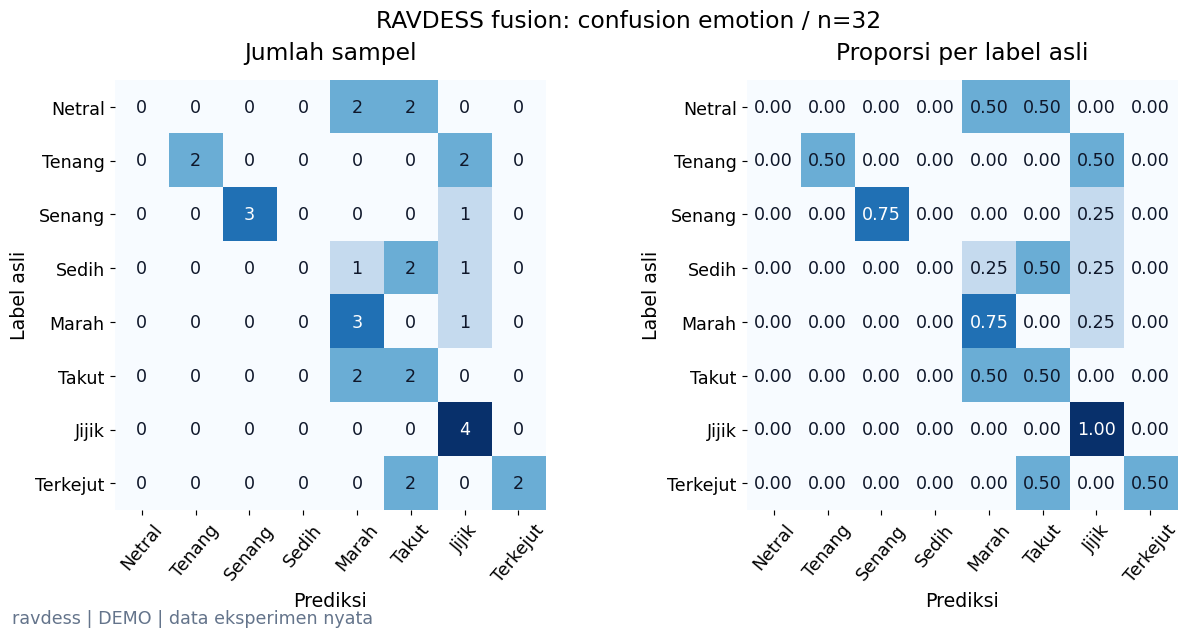

**Yang terlihat:** Sebanyak 16/32 recording diklasifikasikan benar oleh fusion.

**Artinya:** Sel di luar diagonal menunjukkan jenis emosi yang tertukar; warna dinormalisasi per label pada panel kanan.

**Perlu diingat:** Tiap kelas test hanya memiliki empat sampel; satu kesalahan mengubah recall sebesar 0,25.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [12]:
fusion_result = fusion_test_scores['audio_visual']
fig = confusion_pair(fusion_result,list(EMOTIONS.values()),f'RAVDESS fusion: confusion emotion / n={split_sizes["test"]}')
fusion_book.show(fig,'confusion_emotion',
                 f"Sebanyak {np.trace(fusion_result['confusion_matrix'])}/{split_sizes['test']} recording diklasifikasikan benar oleh fusion.",
                 'Sel di luar diagonal menunjukkan jenis emosi yang tertukar; warna dinormalisasi per label pada panel kanan.',
                 'Tiap kelas test hanya memiliki empat sampel; satu kesalahan mengubah recall sebesar 0,25.')

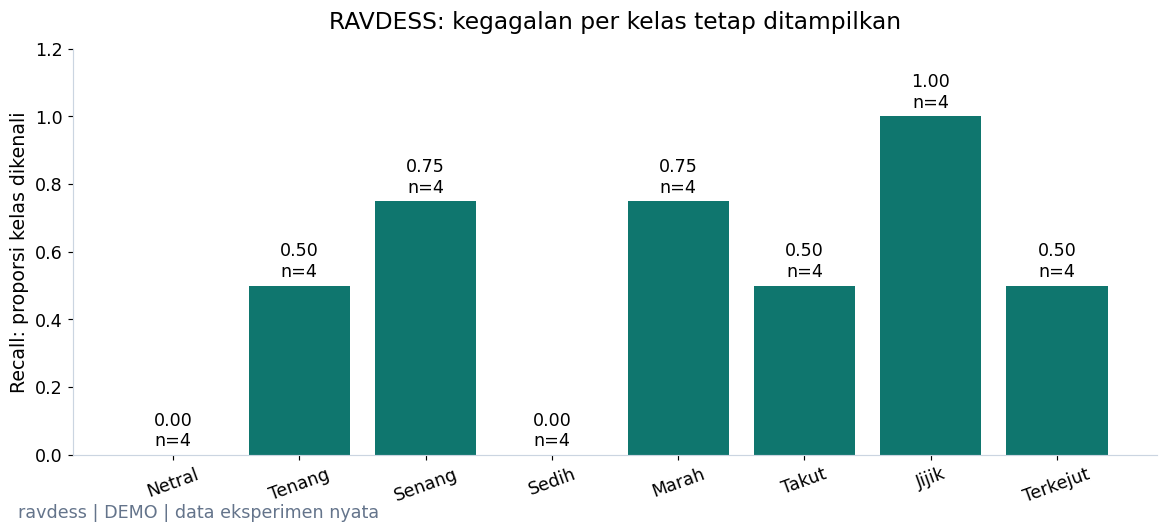

**Yang terlihat:** Kelas dengan recall nol: Netral, Sedih.

**Artinya:** Skor rata-rata belum menjamin semua kelas dikenali; error perlu dilihat per kelas.

**Perlu diingat:** Support kecil membuat perbedaan recall tidak stabil; emotion tetap berbeda dari fatigue.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

,Contoh,Label asli,Prediksi
224,contoh-61881241,Netral,Marah
225,contoh-1b850e2c,Netral,Marah
230,contoh-abfc9b36,Sedih,Marah
231,contoh-a502433b,Sedih,Jijik
234,contoh-82fd7698,Takut,Marah
235,contoh-f74e9b43,Takut,Marah


In [13]:
fig = recall_chart(fusion_result,list(EMOTIONS.values()),'RAVDESS: kegagalan per kelas tetap ditampilkan',COLORS['fusion'])
zero_recall = [EMOTIONS[label] for label in EMOTIONS if fusion_result['classification_report'][str(label)]['recall']==0]
fusion_book.show(fig,'recall_emotion',
                 f'Kelas dengan recall nol: {", ".join(zero_recall) if zero_recall else "tidak ada pada run ini"}.',
                 'Skor rata-rata belum menjamin semua kelas dikenali; error perlu dilihat per kelas.',
                 'Support kecil membuat perbedaan recall tidak stabil; emotion tetap berbeda dari fatigue.')
emotion_errors = public_errors(fusion_predictions,'audio_visual')
for column in ['Label asli','Prediksi']:
    emotion_errors[column] = emotion_errors[column].map(EMOTIONS)
display(emotion_errors)

<a id="5-modalitas-hilang-dan-inference-heldout"></a>

## 5. Modalitas hilang dan inference heldout

**Ablation** menghilangkan satu sumber informasi untuk memeriksa perubahan perilaku model. Di sini semua fitur audio atau semua fitur visual test diberi `NaN`, dan mask ketersediaan dimatikan. Median pengganti tetap berasal dari training.

Ini stress test saat inference; model **tidak dilatih untuk robust terhadap modalitas hilang**. Kita tidak mengganti nilai hilang dengan angka nol yang dianggap sinyal asli.

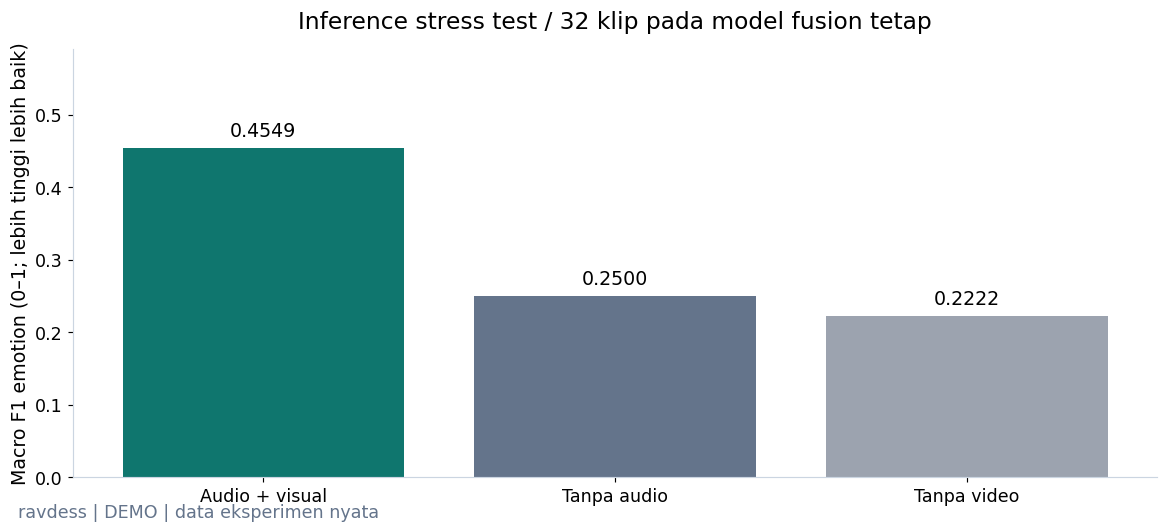

**Yang terlihat:** F1 lengkap 0.4549, tanpa audio 0.2500, tanpa video 0.2222.

**Artinya:** Perbedaan mengukur respons model tetap terhadap gangguan input pada subset ini.

**Perlu diingat:** Ini bukan hasil training missing-modality, bukan jaminan robust di lingkungan ATC.

*Sumber: `20261022T081858104344Z_seed42_75d379` · CACHED + contoh diproses langsung.*

In [14]:
import joblib
fusion_test = fusion_data[fusion_data.split.eq('test')]
fusion_bundle = joblib.load(fusion_run.path / 'models/audio_visual.joblib')
ablation_scores = {}
for modality,columns in [('audio',audio_columns),('video',visual_columns)]:
    masked = fusion_test[fusion_columns].copy()
    masked[columns] = np.nan
    masked[f'{modality}_available'] = False
    predicted = fusion_bundle['model'].predict(masked)
    ablation_scores[f'all_{modality}_missing'] = classification_metrics(fusion_test.target_value,predicted,list(EMOTIONS))
if RUN_MODE=='FULL':
    fusion_metrics['models']['audio_visual']['missing_modality_test'] = ablation_scores
else:
    for scenario in ablation_scores:
        np.testing.assert_allclose(ablation_scores[scenario]['macro_f1'],
            fusion_metrics['models']['audio_visual']['missing_modality_test'][scenario]['macro_f1'])
fig,ax = plt.subplots(layout='constrained')
ablation_values = [fusion_result['macro_f1'],ablation_scores['all_audio_missing']['macro_f1'],ablation_scores['all_video_missing']['macro_f1']]
bars = ax.bar(['Audio + visual','Tanpa audio','Tanpa video'],ablation_values,
              color=[COLORS['fusion'],COLORS['secondary'],COLORS['baseline']])
ax.bar_label(bars,fmt='%.4f',padding=5)
ax.set(ylabel='Macro F1 emotion (0–1; lebih tinggi lebih baik)',ylim=(0,max(ablation_values)*1.3),
       title=f'Inference stress test / {len(fusion_test)} klip pada model fusion tetap')
fusion_book.show(fig,'ablation_modalitas',
                 f'F1 lengkap {ablation_values[0]:.4f}, tanpa audio {ablation_values[1]:.4f}, tanpa video {ablation_values[2]:.4f}.',
                 'Perbedaan mengukur respons model tetap terhadap gangguan input pada subset ini.',
                 'Ini bukan hasil training missing-modality, bukan jaminan robust di lingkungan ATC.')

### Inference langsung dari checkpoint pada contoh holdout

Contoh berikut dipilih deterministik dari bagian test sebelum training, bukan dipilih karena prediksinya benar. Fitur satu klip telah dihitung langsung pada bagian awal. Ketiga checkpoint dimuat lagi dan label asli ditampilkan agar kegagalan juga terlihat. Tidak ada confidence score yang diklaim sebagai jaminan.

In [15]:
live_table = pd.DataFrame([live_paired_features])
inference_rows = []
for model_name in ['audio_only','visual_only','audio_visual']:
    bundle = joblib.load(fusion_run.path / f'models/{model_name}.joblib')
    assert bundle['target']=='emotion'
    prediction = int(bundle['model'].predict(live_table[bundle['feature_columns']])[0])
    inference_rows.append({'Model':model_name,'Contoh':pseudonym(example_id),'Target':'emotion',
                            'Label asli':EMOTIONS[int(heldout_source.target_value)],'Prediksi':EMOTIONS[prediction],
                            'Benar':prediction==int(heldout_source.target_value)})
display(pd.DataFrame(inference_rows))
fusion_book.finish()
if RUN_MODE=='FULL':
    fusion_run.complete(fusion_metrics,{'evaluation_rows':len(fusion_data),'subjects':int(fusion_data.subject_id.nunique()),
                                       'pairing':'same original AV container; source checksums verified',
                                       'subject_overlap':0,'feature_missing_fraction':float(fusion_data[fusion_columns].isna().mean().mean()),
                                       'audio_available':float(fusion_data.audio_available.mean()),
                                       'video_available':float(fusion_data.video_available.mean())},warning_records)

,Model,Contoh,Target,Label asli,Prediksi,Benar
0,audio_only,contoh-61881241,emotion,Netral,Terkejut,False
1,visual_only,contoh-61881241,emotion,Netral,Marah,False
2,audio_visual,contoh-61881241,emotion,Netral,Marah,False


<a id="6-sintesis-kesiapan-penelitian"></a>

## 6. Sintesis kesiapan penelitian

> **Akurasi deteksi fatigue ATC multimodal: BELUM DIUKUR.**  
> **Performa multimodal fatigue ATC belum diukur.**

Empat sumber bukti menjawab pertanyaan yang berbeda. Scorecards berikut mempertahankan nama target, metrik, penyebut, dan sumber run. Tidak ada satu leaderboard yang mencampur Macro F1 dan MAE.

Bagian sintesis dapat menampilkan run audio/visual yang sudah selesai, tetapi eksperimen RAVDESS di atas tidak bergantung pada variabel notebook lain. Jika artefak sintesis belum tersedia, statusnya ditandai belum tersedia tanpa angka pengganti.

In [16]:
synthesis_rows = []
for slug,label,model,metric in [('atcosim_audio','ATCOSIM / ekstraksi',None,None),
                               ('mrl_eye_state','MRL / eye state','hog_linear_svm','macro_f1'),
                               ('drozy_kss','DROZY / KSS sleepiness','ridge_alpha1','mae')]:
    try:
        source_run,source_metrics = cached_run(slug,config)
    except FileNotFoundError:
        synthesis_rows.append({'Bukti':label,'Status':'Belum tersedia lokal','Hasil':'N/A','Sumber run':'N/A'})
        continue
    value = source_metrics['models'][model] if model else None
    if value is not None and metric=='macro_f1': value=value['test']
    result = '114 fitur; tidak ada skor supervised' if value is None else f'{metric} = {value[metric]:.4f}'
    if metric=='macro_f1':
        split = pd.read_csv(source_run.path / 'split_manifest.csv',dtype={'subject_id':str})
        denominator = f"{source_metrics['n_test']} gambar / {split[split.split.eq('test')].subject_id.nunique()} subjek test"
    elif metric=='mae':
        denominator = f"{source_metrics['n_test']} original tests / {source_metrics['n_subjects']} subjek LOSO"
    else:
        denominator = f"{source_run.manifest['n_samples']} ujaran / {source_run.manifest['n_subjects']} speaker"
    synthesis_rows.append({'Bukti':label,'Status':'CACHED FULL terverifikasi','Hasil':result,'Unit / penyebut':denominator,'Sumber run':source_run.manifest['run_id']})
synthesis_rows.append({'Bukti':'RAVDESS / emotion','Status':'FRESH FULL' if RUN_MODE=='FULL' else 'CACHED FULL + inference FRESH',
                        'Hasil':f"Macro F1 = {fusion_result['macro_f1']:.4f}",'Unit / penyebut':f'{len(fusion_test)} klip / 2 aktor test','Sumber run':fusion_run.manifest['run_id']})
display(pd.DataFrame(synthesis_rows))

,Bukti,Status,Hasil,Unit / penyebut,Sumber run
0,ATCOSIM / ekstraksi,CACHED FULL terverifikasi,114 fitur; tidak ada skor supervised,100 ujaran / 1 speaker,20261022T081753373596Z_seed42_72a678
1,MRL / eye state,CACHED FULL terverifikasi,macro_f1 = 0.7877,1159 gambar / 8 subjek test,20261022T082130453246Z_seed42_6453bd
2,DROZY / KSS sleepiness,CACHED FULL terverifikasi,mae = 1.4544,36 original tests / 14 subjek LOSO,20261022T082144167968Z_seed42_60423d
3,RAVDESS / emotion,CACHED FULL + inference FRESH,Macro F1 = 0.4549,32 klip / 2 aktor test,20261022T081858104344Z_seed42_75d379


### Peta kesiapan berbasis bukti

| Komponen | Bukti sekarang | Syarat penelitian ATC berikutnya |
| :--- | :--- | :--- |
| Audio | WAV → 114 fitur + QC | Audio fatigue berlabel dan variasi operator/perangkat |
| Visual | Eye-state model; EAR/window; KSS offline | Kalibrasi closure/blink, kualitas NIR/RGB, waktu label |
| Pairing | AV dari recording RAVDESS yang sama | Audio-video ATC sinkron dari operator/sesi yang sama |
| Modeling | Dummy dan baseline unimodal/static fusion | Ground truth fatigue yang sah, split operator, data temporal cukup |
| Reproduksi | Run unik, config, environment, checkpoints, reload | Protokol preregistered dan validasi eksternal |
| Temporal | Guard urutan tersedia pada package lama | GRU/TCN belum dilatih; perlu baseline dan data berurutan yang valid |

### Ringkasan 90 detik untuk Prof

Kita sudah membuktikan proses input → representasi numerik → model → evaluasi yang dapat diulang. Audio ATC menghasilkan fitur, gambar mata menghasilkan model open/closed, pola mata dipakai untuk regresi sleepiness, dan pasangan AV asli dipakai untuk emotion fusion. Setiap skor punya target dan batasnya sendiri.

Tahap berikutnya memerlukan protokol fatigue bersama Prof, izin rekaman, pasangan audio-video ATC yang sinkron, dan label fatigue independen. Permintaan IEEE sudah dikirim pengguna menurut spesifikasi v3; aksesnya belum tersedia dan korpus itu pun hanya kandidat **audio** fatigue. Kita belum melatih GRU/TCN, belum memvalidasi peringatan real-time, dan belum memiliki skor fatigue ATC multimodal.

## 7. Provenance dan reproduksi

Semua model memakai split aktor yang sudah dibekukan; preprocessing di-fit hanya pada training. FULL menyimpan seluruh artefak ke run baru; DEMO memverifikasi cache/checkpoint lalu menjalankan contoh asli secara langsung. Data mentah, fitur lengkap, model, prediksi per recording, dan executed FULL notebooks tetap lokal.

In [17]:
display(pd.DataFrame([{'Run ID':fusion_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Target':'emotion','Klip':len(fusion_data),'Aktor':fusion_data.subject_id.nunique(),
                       'Model reload':'Diverifikasi pada holdout','Artifact':str(fusion_run.path.relative_to(ROOT)),
                       'Fatigue ATC multimodal':'BELUM DIUKUR'}]))
warning_context.__exit__(None,None,None)

,Run ID,Mode,Target,Klip,Aktor,Model reload,Artifact,Fatigue ATC multimodal
0,20261022T081858104344Z_seed42_75d379,DEMO,emotion,128,8,Diverifikasi pada holdout,runs/ravdess_emotion/20261022T081858104344Z_se...,BELUM DIUKUR


Untuk presentasi, gunakan mode default DEMO dan ikuti rute di awal. Untuk mengulang feature extraction/training, gunakan `--mode FULL` pada [runner v3](../../scripts/10_execute_notebook_v3.py). Run baru tidak menggantikan hasil lama. [Panduan lengkap](README.md).